# CheXagent-2-3b Fine-Tuning — Phrase Grounding (Kaggle T4)

**Setup Kaggle sebelum run:**
1. Upload dataset VinDR-CXR ke Kaggle Datasets → path akan jadi `/kaggle/input/vindr-cxr/`
2. Upload `train.parquet`, `val.parquet`, `test.parquet` ke Kaggle Datasets tersendiri
3. Di notebook settings: **Accelerator → GPU T4 x1**, **Internet → On**
4. Tambah secret `HFTOKEN` di Kaggle Secrets (Settings → Add-ons → Secrets)

## STEP 1 — Install

In [1]:
# import subprocess, sys

# pkgs = [
#     'transformers==4.40.0',
#     'peft==0.10.0',
#     'accelerate==0.29.3',
#     'sentencepiece',
#     'einops',
#     'pydicom',
# ]
# for pkg in pkgs:
#     r = subprocess.run(
#         [sys.executable, '-m', 'pip', 'install', pkg, '-q', '--no-cache-dir'],
#         capture_output=True, text=True
#     )
#     print(f"{'OK' if r.returncode==0 else 'FAIL'} {pkg}")

## STEP 2 — Patch pytorch_utils.py

In [2]:
# import sys, subprocess
# r = subprocess.run(
#     [sys.executable, '-c',
#      'import transformers, os; print(os.path.join(os.path.dirname(transformers.__file__), "pytorch_utils.py"))'],
#     capture_output=True, text=True
# )
# path = r.stdout.strip()
# with open(path) as f:
#     content = f.read()
# if 'is_torch_greater_or_equal_than_2_3' not in content:
#     with open(path, 'a') as f:
#         f.write("""
# # === PATCH ===
# import torch as _tp
# _v = tuple(int(x) for x in _tp.__version__.split("+")[0].split("."))
# is_torch_greater_or_equal_than_2_3 = _v >= (2, 3)
# is_torch_greater_or_equal_than_2_4 = _v >= (2, 4)
# is_torch_greater_or_equal_than_2_5 = _v >= (2, 5)
# """)
#     print('Patch OK:', path)
# else:
#     print('Patch sudah ada.')

In [3]:
# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [4]:
# import torch
# print(torch.cuda.device_count())

In [1]:
!where python

t:\nicho\.venv2\Scripts\python.exe
C:\Users\Salam-Maintenance\AppData\Local\Microsoft\WindowsApps\python.exe
C:\Users\Salam-Maintenance\AppData\Local\Python\bin\python.exe


## STEP 3 — Import & Verifikasi

In [1]:
import os, re, gc, sys, warnings, tempfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from tqdm.auto import tqdm
from PIL import Image
import pydicom
import cv2

os.environ["HF_HOME"] = "T:/huggingface_cache"
import transformers
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, AutoProcessor,
    TrainingArguments, Trainer, EarlyStoppingCallback, 
)
from peft import LoraConfig, get_peft_model, TaskType, PeftModel

warnings.filterwarnings('ignore')

assert transformers.__version__ == '4.40.0'

print('transformers :', transformers.__version__)
print('numpy        :', np.__version__)
print('torch        :', torch.__version__)
print('CUDA         :', torch.cuda.is_available())
print('GPU          :', torch.cuda.get_device_name(0))
print('VRAM         :', round(torch.cuda.get_device_properties(0).total_memory/1e9, 1), 'GB')
print('OK')

t:\nicho\.venv2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers : 4.40.0
numpy        : 2.4.6
torch        : 2.5.1+cu121
CUDA         : True
GPU          : NVIDIA GeForce RTX 2070 SUPER
VRAM         : 8.6 GB
OK


## STEP 4 — Konfigurasi Path (Kaggle)

In [2]:
# ── Sesuaikan nama dataset Kaggle kamu ──────────────────────────────────
# Cek path dengan: import os; print(os.listdir('/kaggle/input/'))

DICOM_DIR    = './vindr'          # folder berisi file .dicom
DATASET_PATH = './vindr-cxr' # folder berisi train/val/test.parquet
OUTPUT_DIR   = './output-indo-pre'
MODEL_NAME   = 'StanfordAIMI/CheXagent-2-3b'

MAX_LENGTH   = 1200
BATCH_SIZE   = 1
GRAD_ACCUM   = 8     
NUM_EPOCHS = 1
LR           = 2e-5

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Cek isi /kaggle/input/
# print('Kaggle input datasets:')
# for d in sorted(os.listdir('/kaggle/input')):
#     files = os.listdir(f'/kaggle/input/{d}')[:5]
#     print(f'  /kaggle/input/{d}/ → {files}')
print()
print('Config OK')


Config OK


## STEP 5 — HuggingFace Login & Load Data

In [3]:
# from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

# secrets = UserSecretsClient()
# hf_token = secrets.get_secret('HFTOKEN')
import os; login(os.getenv("HF_TOKEN"))
print('HF login OK')

HF login OK


In [4]:
train_df = pd.read_parquet(os.path.join(DATASET_PATH, 'train.parquet'))
val_df   = pd.read_parquet(os.path.join(DATASET_PATH, 'val.parquet'))
test_df  = pd.read_parquet(os.path.join(DATASET_PATH, 'test.parquet'))

print(f'Train : {len(train_df):,}')
print(f'Val   : {len(val_df):,}')
print(f'Test  : {len(test_df):,}')
display(train_df.head(3))
# print(os.path.join(DATASET_PATH, 'train.parquet'))

Train : 12,467
Val   : 1,568
Test  : 1,562


,image_id,query,response
0,1bf31ecce06f5cab7b82b36daea676b6,Ada berapa banyak temuan?,"<|ref|>Aortic enlargement<|/ref|><|box|>(0, 74..."
1,1bf31ecce06f5cab7b82b36daea676b6,Kelainan apa yang terlihat?,"<|ref|>Aortic enlargement<|/ref|><|box|>(0, 74..."
2,1bf31ecce06f5cab7b82b36daea676b6,Di mana Aortic enlargement?,"<|ref|>Aortic enlargement<|/ref|><|box|>(0, 74..."


In [5]:
train_df.iloc[0]["response"]

'<|ref|>Aortic enlargement<|/ref|><|box|>(0, 74), (5, 82)<|/box|>'

In [6]:
# def has_bbox(text):
#     return bool(re.search(r'\[\d+[,\s]+\d+[,\s]+\d+[,\s]+\d+\]', str(text)))

# train_df_grounding = train_df[train_df['response'].apply(has_bbox)].reset_index(drop=True)
# val_df_grounding   = val_df[val_df['response'].apply(has_bbox)].reset_index(drop=True)
# test_df_grounding  = test_df[test_df['response'].apply(has_bbox)].reset_index(drop=True)

# print(f"Train: {len(train_df):,} → {len(train_df_grounding):,} (hanya bbox)")
# print(f"Val  : {len(val_df):,} → {len(val_df_grounding):,}")
# print(f"Test : {len(test_df):,} → {len(test_df_grounding):,}")

# train_df = train_df_grounding.copy()
# val_df = val_df_grounding.copy()
# test_df = test_df_grounding.copy()

## STEP 6 — Load Model
T4 16GB → tidak perlu CPU offload, semua muat di GPU.

In [7]:
print('Loading tokenizer...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
processor = AutoProcessor.from_pretrained(MODEL_NAME, trust_remote_code=True)
print('Tokenizer OK')

Loading tokenizer...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Tokenizer OK


In [21]:
print('Loading model (bfloat16)...')

# bnb_config = BitsAndBytesConfig(
#     load_in_4bit=True,
#     bnb_4bit_quant_type="nf4",
#     bnb_4bit_compute_dtype=torch.bfloat16, # Tetap kencang di RTX 4060
#     bnb_4bit_use_double_quant=True
# )
import os


model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
    # quantization_config=bnb_config, 
    torch_dtype=torch.bfloat16,
    device_map={'':0}
)
model = model.to("cuda")

# Freeze visual encoder
for param in model.model.visual.parameters():
    param.requires_grad = False

vram_used = torch.cuda.memory_allocated()/1e9
vram_total = torch.cuda.get_device_properties(0).total_memory/1e9
print(f'VRAM dipakai : {vram_used:.2f} GB')
print(f'VRAM bebas   : {vram_total - vram_used:.2f} GB')
print(f'Device       : {next(model.parameters()).device}')

Loading model (bfloat16)...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Loading checkpoint shards: 100%|██████████| 3/3 [06:31<00:00, 130.48s/it]


VRAM dipakai : 12.61 GB
VRAM bebas   : -4.02 GB
Device       : cuda:0


In [9]:
print(next(model.parameters()).dtype)

torch.bfloat16


## STEP 7 — Setup LoRA

In [10]:
# from peft import PeftModel
# LORA_PATH = "./output/lora_adapter"   # atau folder adapter hasil training
# model = PeftModel.from_pretrained(
#     model,
#     LORA_PATH
# )
# model.eval()

In [11]:
model.gradient_checkpointing_enable()
model.enable_input_require_grads()

lora_config = LoraConfig(
    r=16,                        # T4 16GB bisa pakai r=16
    lora_alpha=16,
    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj',
                    'gate_proj', 'up_proj', 'down_proj'],
    lora_dropout=0.05,
    bias='none',
    task_type=TaskType.CAUSAL_LM,
)

model = get_peft_model(model, lora_config)
# model = PeftModel.from_pretrained(model, "./output/lora_adapter", is_trainable=True)
# model = PeftModel.from_pretrained(model, "./output/lora_adapter")
model.print_trainable_parameters()

gc.collect()
torch.cuda.empty_cache()
vram_used = torch.cuda.memory_allocated()/1e9
vram_total = torch.cuda.get_device_properties(0).total_memory/1e9
print(f'VRAM setelah LoRA : {vram_used:.2f} GB')
print(f'VRAM bebas        : {vram_total - vram_used:.2f} GB')

trainable params: 10,223,616 || all params: 3,150,970,368 || trainable%: 0.32445928733024504
VRAM setelah LoRA : 6.31 GB
VRAM bebas        : 2.28 GB


## STEP 8 — Dataset Class

In [9]:
def is_valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except:
        return False

In [20]:
# SYSTEM_PROMPT = (
#     "You are a radiology AI assistant. "
#     "When answering questions about chest X-rays, always mention the finding "
#     "using the format <|ref|>finding_name<|/ref|>, followed immediately by "
#     "its normalized bounding box using the format "
#     "<|box|>(x1,y1),(x2,y2)<|/box|>. "
#     "All bounding box coordinates must be normalized integers in the range 0–99. "
#     "If multiple findings are mentioned, provide each finding with its own "
#     "<|ref|> and <|box|> pair."
# )
SYSTEM_PROMPT = (
    'Kamu adalah asisten AI radiologi. '
    'Ketika ditanya tentang temuan pada foto rontgen dada, jawab dengan nama temuan berformat <|ref|>nama_temuan<|/ref|>'
    'diikuti koordinat bounding box yang dinormalisasi dengan nilai antara 0 hingga 100 dalam format<|box|>(x1,y1),(x2,y2)<|/box|>.'
    'Jika ada lebih dari 1 temuan, berikan setiap temuan sepasang <|ref|> dan <|box|>'
)
def dicom_to_pil(image_id: str) -> Image.Image:
    # Cari file .dicom — bisa tersimpan flat atau dalam subfolder
    candidates = [
        os.path.join(DICOM_DIR, f'{image_id}.dicom'),
        os.path.join(DICOM_DIR, f'{image_id}.dcm'),
        os.path.join(DICOM_DIR, 'train_images', f'{image_id}.dicom'),
        os.path.join(DICOM_DIR, 'test_images',  f'{image_id}.dicom'),
    ]
    path = next((p for p in candidates if os.path.exists(p)), None)
    if path is None:
        print(f'[WARN] File tidak ditemukan: {image_id}')
        return Image.new('RGB', (512, 512), 0)
    try:
        dcm = pydicom.dcmread(path)
        arr = dcm.pixel_array.astype(np.float32)
        lo, hi = arr.min(), arr.max()
        if hi > lo:
            arr = (arr - lo) / (hi - lo)
        arr = (arr * 255).astype(np.uint8)
        
        # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        arr = clahe.apply(arr)
        
        return Image.fromarray(arr).convert('RGB')
    except Exception as e:
        print(f'[WARN] DICOM {image_id}: {e}')
        return Image.new('RGB', (512, 512), 0)


CACHE_DIR = "./png_cache_pre"
os.makedirs(CACHE_DIR, exist_ok=True)
import time
from tqdm import tqdm
from joblib import Parallel, delayed

image_ids = np.union1d(
    train_df["image_id"].values, 
    np.union1d(val_df["image_id"].values, test_df["image_id"].values)
)

start = time.time()
pbar = tqdm(total=len(image_ids), desc="Caching")

def process(image_id):
    path = os.path.join(CACHE_DIR, f"{image_id}.png")
    if not os.path.exists(path):
        img = dicom_to_pil(image_id)
        img.save(path, "PNG")
    pbar.update(1)

Parallel(n_jobs=6, backend="threading")(
    delayed(process)(i) for i in image_ids
)

pbar.close()

print("Total time:", time.time() - start, "seconds")



class GroundingDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=MAX_LENGTH):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_length
        self.img_tok   = tokenizer.convert_tokens_to_ids('<image>')

    def __len__(self):
        return len(self.df)

    def _empty(self):
        ids = torch.zeros(self.max_len, dtype=torch.long)
        return {
            'input_ids':      ids,
            'attention_mask': torch.zeros(self.max_len, dtype=torch.long),
            'labels':         torch.full((self.max_len,), -100, dtype=torch.long),
        }

    def __getitem__(self, idx):
        row      = self.df.iloc[idx]
        image_id = str(row['image_id'])
        question = str(row['query'])
        answer   = str(row['response'])
    
        try:
            img_path = os.path.join(CACHE_DIR, f"{image_id}.png")

    
            if not os.path.exists(img_path):
                print(f"[WARN] missing cache: {image_id}")
                img_path = None
            
            if (img_path is None) or (not os.path.exists(img_path)) or (not is_valid_image(img_path)):
                return self._empty()


            fq = self.tokenizer.from_list_format([
                {"image": img_path},
                {"text": question},
            ])
    
            full_conv = [
                {"from": "system", "value": SYSTEM_PROMPT},
                {"from": "human",  "value": fq},
                {"from": "gpt",    "value": answer},
            ]
    
            instr_conv = [
                {"from": "system", "value": SYSTEM_PROMPT},
                {"from": "human",  "value": fq},
            ]
    
            full_tok = self.tokenizer.apply_chat_template(
                full_conv,
                add_generation_prompt=False,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
                padding="max_length",
                max_length=self.max_len,
                truncation=True,
            )
    
            instr_tok = self.tokenizer.apply_chat_template(
                instr_conv,
                add_generation_prompt=True,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
            )
    
            instr_len = instr_tok["input_ids"].shape[-1]
            instr_len = min(instr_len, full_tok["input_ids"].shape[1] - 1)
    
            ids = full_tok["input_ids"].squeeze(0)
    
            if (ids == self.img_tok).sum().item() == 0:
                print(f"[WARN] image token hilang: {image_id}")
                return self._empty()
    
            labels = full_tok["input_ids"].squeeze(0).clone()

            input_ids = labels.clone()

            # cari boundary secara aman:
            instr_len = instr_tok["input_ids"].shape[-1]
            instr_len = min(instr_len, input_ids.shape[0])

            # mask hanya prompt
            labels[:instr_len] = -100

            # mask padding
            labels[input_ids == self.tokenizer.pad_token_id] = -100
    
            return {
                "input_ids": ids,
                "attention_mask": full_tok["attention_mask"].squeeze(0),
                "labels": labels.squeeze(0),
            }
    
        except Exception as e:
            print(f"[WARN] {image_id}: {e}")
            return self._empty()
def bersihkan_dataframe(df, tokenizer):
    valid_indices = []
    alasan = {
        "missing_image": 0,
        "invalid_image": 0,
        "empty_query": 0,
        "empty_response": 0,
        "no_image_token": 0,
        "no_response_token": 0,
        "exception": 0,
    }

    img_tok = tokenizer.convert_tokens_to_ids("<image>")

    for idx, row in tqdm(df.iterrows(), total=len(df)):
        image_id = str(row["image_id"])
        query = str(row["query"])
        response = str(row["response"])

        img_path = os.path.join(CACHE_DIR, f"{image_id}.png")

        # -----------------------------
        # cek image
        # -----------------------------
        if not os.path.exists(img_path):
            alasan["missing_image"] += 1
            continue

        if not is_valid_image(img_path):
            alasan["invalid_image"] += 1
            continue

        # -----------------------------
        # cek query
        # -----------------------------
        if query.strip() == "":
            alasan["empty_query"] += 1
            continue

        # -----------------------------
        # cek response
        # -----------------------------
        if response.strip() == "":
            alasan["empty_response"] += 1
            continue

        try:

            fq = tokenizer.from_list_format([
                {"image": img_path},
                {"text": query},
            ])

            full_conv = [
                {"from": "system", "value": SYSTEM_PROMPT},
                {"from": "human", "value": fq},
                {"from": "gpt", "value": response},
            ]

            instr_conv = [
                {"from": "system", "value": SYSTEM_PROMPT},
                {"from": "human", "value": fq},
            ]

            full_tok = tokenizer.apply_chat_template(
                full_conv,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
                padding="max_length",
                truncation=True,
                max_length=MAX_LENGTH,
            )

            instr_tok = tokenizer.apply_chat_template(
                instr_conv,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
                add_generation_prompt=True,
            )

            ids = full_tok["input_ids"].squeeze(0)

            # -----------------------------
            # image token harus ada
            # -----------------------------
            if (ids == img_tok).sum().item() == 0:
                alasan["no_image_token"] += 1
                continue

            labels = ids.clone()

            instr_len = min(
                instr_tok["input_ids"].shape[-1],
                labels.shape[0]
            )

            labels[:instr_len] = -100
            labels[ids == tokenizer.pad_token_id] = -100

            # -----------------------------
            # response token harus ada
            # -----------------------------
            if (labels != -100).sum().item() == 0:
                alasan["no_response_token"] += 1
                continue

            valid_indices.append(idx)

        except Exception as e:
            alasan["exception"] += 1
            print(f"[ERROR] {image_id}: {e}")

    print("=" * 60)
    print("Ringkasan pembersihan dataframe")
    print("=" * 60)

    for k, v in alasan.items():
        print(f"{k:20s}: {v}")

    print("-" * 60)
    print(f"Awal : {len(df)}")
    print(f"Valid: {len(valid_indices)}")
    print(f"Dibuang: {len(df)-len(valid_indices)}")
    print("=" * 60)

    return df.loc[valid_indices].reset_index(drop=True)

# Bersihkan train dan val dataframe dari data hantu/korup
# print(f"Jumlah awal train_df: {len(train_df)}")
# print(f"Jumlah awal val_df: {len(val_df)}")
train_df = bersihkan_dataframe(train_df, tokenizer)
val_df = bersihkan_dataframe(val_df, tokenizer)
# print(f"Jumlah train_df setelah dibersihkan: {len(train_df)}")
# print(f"Jumlah val_df setelah dibersihkan: {len(val_df)}")

# Baru masukkan ke dataset setelah bersih
train_dataset = GroundingDataset(train_df, tokenizer)
val_dataset   = GroundingDataset(val_df,   tokenizer)

# val_dataset = torch.utils.data.Subset(val_dataset, [0])
print(train_df.shape)
print(val_df.shape)
print(test_df.shape)
print(len(train_dataset))
s = train_dataset[1]
n_resp = (s['labels'] != -100).sum().item()
print(f'input_ids      : {s["input_ids"].shape}')
valid = 0
for i in range(100):
    s = train_dataset[i]
    n = (s["labels"] != -100).sum().item()
    if n > 0:
        valid += 1

print("valid ratio:", valid/100)
print(f'response tokens: {n_resp}  <- harus > 0')
assert n_resp > 0, 'ERROR: response tokens = 0'
print('Dataset OK')

Caching:   0%|          | 0/3892 [00:00<?, ?it/s]


Total time: 0.004004955291748047 seconds


100%|██████████| 12467/12467 [05:33<00:00, 37.40it/s] 


Ringkasan pembersihan dataframe
missing_image       : 8974
invalid_image       : 1
empty_query         : 0
empty_response      : 0
no_image_token      : 0
no_response_token   : 321
exception           : 0
------------------------------------------------------------
Awal : 12467
Valid: 3171
Dibuang: 9296


100%|██████████| 1568/1568 [00:34<00:00, 45.09it/s] 


Ringkasan pembersihan dataframe
missing_image       : 1196
invalid_image       : 0
empty_query         : 0
empty_response      : 0
no_image_token      : 0
no_response_token   : 36
exception           : 0
------------------------------------------------------------
Awal : 1568
Valid: 336
Dibuang: 1232
(3171, 3)
(336, 3)
(1562, 3)
3171
input_ids      : torch.Size([1200])
valid ratio: 1.0
response tokens: 8  <- harus > 0
Dataset OK


In [11]:
test_df["response"].isna().sum()

np.int64(0)

## STEP 9 — Collate & Trainer

In [ ]:
def collate_fn(batch):
    return {
        'input_ids':      torch.stack([b['input_ids']      for b in batch]),
        'attention_mask': torch.stack([b['attention_mask'] for b in batch]),
        'labels':         torch.stack([b['labels']         for b in batch]),
    }


class NoMoveTrainer(Trainer):
    """Skip _move_model_to_device — model sudah di GPU yang benar."""
    def _move_model_to_device(self, model, device):
        pass


training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    lr_scheduler_type='cosine',
    warmup_ratio=0.05,
    weight_decay=0.01,
    fp16=False,
    bf16=True,
    gradient_checkpointing=True,
    optim='adamw_torch',
    logging_steps=50,
    evaluation_strategy='steps',
    eval_steps=500,
    save_strategy='steps',
    save_steps=500,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    save_total_limit=20,
    remove_unused_columns=False,
    dataloader_num_workers=0,   
    report_to='none',
)




trainer = NoMoveTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=collate_fn,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print('Trainer siap')

Berhasil mem-patch 32 modul PhiAttention ke BFloat16.
Trainer siap


In [10]:
import types
from transformers.models.phi.modeling_phi import PhiAttention

# Ambil fungsi forward asli
original_phi_attn_forward = PhiAttention.forward

def uncasted_forward(self, hidden_states, *args, **kwargs):
    # Pastikan di-cast ke bfloat16, karena training_args menggunakan bf16=True
    if isinstance(hidden_states, torch.Tensor):
        hidden_states = hidden_states.to(torch.bfloat16)
    
    return original_phi_attn_forward(self, hidden_states, *args, **kwargs)

# Terapkan patch ke model
patched_count = 0
for name, module in model.named_modules():
    if module.__class__.__name__ == "PhiAttention":
        module.forward = types.MethodType(uncasted_forward, module)
        patched_count += 1

print(f"Berhasil mem-patch {patched_count} modul PhiAttention ke BFloat16.")

Berhasil mem-patch 32 modul PhiAttention ke BFloat16.


## STEP 10 — Training

In [11]:
# visual = model.base_model.model.model.visual

# print(next(visual.parameters()).dtype)

In [12]:
# visual = model.base_model.model.model.visual

# visual.half()

In [13]:
# model.base_model.visual

In [14]:
# Ambil modul visual
# visual = model.base_model.model.model.visual
visual = model.base_model.visual
print("Dtype awal visual:", next(visual.parameters()).dtype)

# PAKSA KE BFLOAT16 (Jangan gunakan .half() karena .half() itu Float16!)
visual.to(torch.bfloat16) 
print("Dtype setelah diubah:", next(visual.parameters()).dtype)

Dtype awal visual: torch.float32
Dtype setelah diubah: torch.bfloat16


In [ ]:
nan_count = sum(
    1 for _, p in model.named_parameters()
    if p.requires_grad and torch.isnan(p).any()
)

print("NaN params:", nan_count)

NaN params: 0


In [ ]:
print("args.max_steps:", trainer.args.max_steps)
print("state.max_steps:", trainer.state.max_steps)
print("global_step:", trainer.state.global_step)
print("epoch:", trainer.state.epoch)

args.max_steps: -1
state.max_steps: 0
global_step: 0
epoch: None


In [ ]:
gc.collect()
torch.cuda.empty_cache()

vram_used  = torch.cuda.memory_allocated()/1e9
vram_total = torch.cuda.get_device_properties(0).total_memory/1e9
print(f'VRAM dipakai   : {vram_used:.2f} GB')
print(f'VRAM bebas     : {vram_total - vram_used:.2f} GB')
print(f'Mulai training...')

result = trainer.train()
# result = trainer.train(resume_from_checkpoint='./output/checkpoint-5000')

adapter_path = os.path.join(OUTPUT_DIR, 'lora_adapter')
model.save_pretrained(adapter_path)
tokenizer.save_pretrained(adapter_path)
trainer.save_metrics('train', result.metrics)

print('Selesai!')
print(result.metrics)

VRAM dipakai   : 6.31 GB
VRAM bebas     : 2.27 GB
Mulai training...


  2%|▏         | 50/3012 [29:55<29:27:24, 35.80s/it]

{'loss': 4.5744, 'grad_norm': 3.828125, 'learning_rate': 1.655629139072848e-05, 'epoch': 0.03}


  3%|▎         | 100/3012 [1:00:17<29:26:58, 36.41s/it]

{'loss': 3.4454, 'grad_norm': 2.328125, 'learning_rate': 3.311258278145696e-05, 'epoch': 0.07}


  5%|▍         | 150/3012 [1:30:41<28:58:58, 36.46s/it]

... (125 outputs left out)

                                                      
100%|█████████▉| 3000/3012 [34:28:04<10:25, 52.14s/it]

{'eval_loss': 0.3322153091430664, 'eval_runtime': 1488.8096, 'eval_samples_per_second': 0.984, 'eval_steps_per_second': 0.984, 'epoch': 1.99}


100%|██████████| 3012/3012 [34:38:40<00:00, 41.41s/it]   


{'train_runtime': 124720.6572, 'train_samples_per_second': 0.193, 'train_steps_per_second': 0.024, 'train_loss': 0.4958341795293142, 'epoch': 2.0}
Selesai!
{'train_runtime': 124720.6572, 'train_samples_per_second': 0.193, 'train_steps_per_second': 0.024, 'total_flos': 5.237438730338304e+17, 'train_loss': 0.4958341795293142, 'epoch': 1.9988386561592701}


## STEP 11 — Evaluasi Test Set

In [ ]:
print("before ", len(test_df))
test_df = bersihkan_dataframe(test_df,tokenizer)
print("after ", len(test_df))


before  1647


100%|██████████| 1647/1647 [00:08<00:00, 203.49it/s]

Ringkasan pembersihan dataframe
missing_image       : 0
invalid_image       : 9
empty_query         : 0
empty_response      : 0
no_image_token      : 0
no_response_token   : 158
exception           : 0
------------------------------------------------------------
Awal : 1647
Valid: 1480
Dibuang: 167
after  1480


In [ ]:
test_dataset = GroundingDataset(test_df, tokenizer)
metrics      = trainer.evaluate(test_dataset)

print('=== Test Metrics ===')
for k, v in metrics.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

100%|██████████| 1480/1480 [24:32<00:00,  1.01it/s]

=== Test Metrics ===
  eval_loss: 0.3301
  eval_runtime: 1473.3342
  eval_samples_per_second: 1.0050
  eval_steps_per_second: 1.0050
  epoch: 1.9988


## STEP 12 — Inference & Visualisasi

In [15]:
model

CheXagentForCausalLM(
  (model): CheXagentModel(
    (embed_tokens): Embedding(51200, 2560)
    (embed_dropout): Dropout(p=0.0, inplace=False)
    (layers): ModuleList(
      (0-31): 32 x PhiDecoderLayer(
        (self_attn): PhiAttention(
          (q_proj): Linear(in_features=2560, out_features=2560, bias=True)
          (k_proj): Linear(in_features=2560, out_features=2560, bias=True)
          (v_proj): Linear(in_features=2560, out_features=2560, bias=True)
          (dense): Linear(in_features=2560, out_features=2560, bias=True)
          (rotary_emb): PhiRotaryEmbedding()
        )
        (mlp): PhiMLP(
          (activation_fn): NewGELUActivation()
          (fc1): Linear(in_features=2560, out_features=10240, bias=True)
          (fc2): Linear(in_features=10240, out_features=2560, bias=True)
        )
        (input_layernorm): LayerNorm((2560,), eps=1e-05, elementwise_affine=True)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
    )
    (final_layernorm): LayerN

In [22]:
from peft import PeftModel
# LORA_PATH = "./output-indo-1/lora_adapter"   # atau folder adapter hasil training
LORA_PATH = "./output-eng-1/lora_adapter"   # atau folder adapter hasil training
model = PeftModel.from_pretrained(
    model,
    LORA_PATH
)
model.eval()

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): CheXagentForCausalLM(
      (model): CheXagentModel(
        (embed_tokens): Embedding(51200, 2560)
        (embed_dropout): Dropout(p=0.0, inplace=False)
        (layers): ModuleList(
          (0-31): 32 x PhiDecoderLayer(
            (self_attn): PhiAttention(
              (q_proj): lora.Linear(
                (base_layer): Linear(in_features=2560, out_features=2560, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=2560, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=2560, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
              )
              (k_proj): lora.Lin

In [23]:
test_df.columns

Index(['image_id', 'query', 'response'], dtype='str')

In [24]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# SYSTEM_PROMPT = '''You are a professional radiologist and will be given a patient's X-ray image and a question specific to the image.
# Respond to the question related to the X-ray image concisely and accurately.
# IMPORTANT: After providing your answer, include the bounding box coordinates that highlight the relevant area inside the <|box|>...<|/box|> tags.'''

SYSTEM_PROMPT = (
    'Kamu adalah asisten AI radiologi. '
    'Ketika ditanya tentang temuan pada foto rontgen dada, jawab dengan nama temuan berformat <|ref|>nama_temuan<|/ref|>'
    'diikuti koordinat bounding box yang dinormalisasi dengan nilai antara 0 hingga 100 dalam format<|box|>(x1,y1),(x2,y2)<|/box|>.'
    'Jika ada lebih dari 1 temuan, berikan setiap temuan sepasang <|ref|> dan <|box|>'
)
def parse_label(text):
    if text is None:
        return None

    m = re.search(r"<\|ref\|>\s*(.*?)\s*<\|/ref\|>", str(text))
    return m.group(1).strip() if m else None


def parse_bbox_by_label(text, target_label):
    if text is None or target_label is None:
        return None

    pattern = (
        r"<\|ref\|>\s*(.*?)\s*<\|/ref\|>"
        r"\s*<\|box\|>\s*\((\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\)\s*<\|/box\|>"
    )

    matches = re.findall(pattern, str(text))

    for label, x1, y1, x2, y2 in matches:
        if label.strip().lower() == target_label.strip().lower():
            return [int(x1), int(y1), int(x2), int(y2)]

    return None

def parse_bbox(text):
    """
    Parse:
    <|box|>(40, 44), (87, 59)<|/box|>

    menjadi:
    [40, 44, 87, 59]
    """

    if text is None:
        return None

    text = str(text)

    # ambil isi tag box jika ada
    m = re.search(r"<\|box\|>(.*?)<\|/box\|>", text)
    if m:
        text = m.group(1)

    nums = list(map(int, re.findall(r"\d+", text)))

    if len(nums) >= 4:
        return nums[:4]

    return None

def parse_all_boxes(text):
    pattern = (
        r"<\|ref\|>\s*(.*?)\s*<\|/ref\|>"
        r"\s*<\|box\|>\s*\((\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\)\s*<\|/box\|>"
    )

    results = {}

    for label, x1, y1, x2, y2 in re.findall(pattern, str(text)):
        label = label.strip()

        results.setdefault(label, []).append(
            [int(x1), int(y1), int(x2), int(y2)]
        )

    return results


def compute_iou(a, b):
    ix1 = max(a[0],b[0]); iy1 = max(a[1],b[1])
    ix2 = min(a[2],b[2]); iy2 = min(a[3],b[3])
    inter = max(0,ix2-ix1)*max(0,iy2-iy1)
    union = (a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-inter
    return inter/union if union > 0 else 0.0


@torch.inference_mode()
def predict(image_id: str, question: str, target_label=None, max_new_tokens=128):
    img_path = os.path.join(CACHE_DIR, f"{image_id}.png")
    if not os.path.exists(img_path):
        print(f"[WARN] missing cache: {image_id}")
        img_path = None
    
    if (img_path is None) or (not os.path.exists(img_path)) or (not is_valid_image(img_path)):
        return self._empty()
    with Image.open(img_path) as image:
        image = image.copy()
    try:
        fq = tokenizer.from_list_format([{'image': img_path}, {'text': question}])
        conv = [
            {'from': 'system', 'value': SYSTEM_PROMPT},
            {'from': 'human',  'value': fq},
        ]
        inputs = tokenizer.apply_chat_template(
            conv, add_generation_prompt=True,
            tokenize=True, return_dict=True, return_tensors='pt'
        ).to(model.device)
        
        out      = model.generate(**inputs, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id)
        response = tokenizer.decode(
            out[0][inputs['input_ids'].shape[-1]:],
            skip_special_tokens=True
        )
        bbox = (
            parse_bbox_by_label(response, target_label)
            if target_label is not None
            else parse_bbox(response)
        )

        return {
            'response': response,
            'bbox': bbox,
            'image': image
        }
    finally:
        try:
            os.remove(tmp_path)
        except Exception:
            pass


def visualize(result, image_id, gt_bbox=None):
    img  = result['image']
    w, h = img.size
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(img, cmap='gray')
    ax.set_title(image_id, fontsize=10)
    if result['bbox']:
        x1,y1,x2,y2 = [v/100 for v in result['bbox']]
        ax.add_patch(mpatches.Rectangle(
            (x1*w,y1*h),(x2-x1)*w,(y2-y1)*h,
            lw=2,edgecolor='red',facecolor='none',label='Predicted'))
    if gt_bbox:
        gx1,gy1,gx2,gy2 = [v/100 for v in gt_bbox]
        ax.add_patch(mpatches.Rectangle(
            (gx1*w,gy1*h),(gx2-gx1)*w,(gy2-gy1)*h,
            lw=2,edgecolor='lime',facecolor='none',
            linestyle='--',label='Ground Truth'))
        if result['bbox']:
            iou = compute_iou(result['bbox'], gt_bbox)
            ax.set_xlabel(f'IoU = {iou:.3f}', fontsize=11)
    ax.legend()
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Response:', result['response'])


# Test inference
row = test_df.sample(1, random_state=90).iloc[0]
# row["query"] = "Locate the Pulmonary fibrosis?"

gt_label = parse_label(row["response"])
gt_box   = parse_bbox_by_label(row["response"], gt_label)

print("Query :", row["query"])
print("GT Label :", gt_label)
print("GT :", row["response"])

CACHE_DIR = "./png_cache_pre"
result = predict(
    row["image_id"],
    # row["query"],
    "Where is Calcification?",
    target_label=gt_label
)

print("Response :", result["response"])
print("Pred Box :", result["bbox"])

visualize(result, row["image_id"], gt_box)

Query : Apakah ada Calcification?
GT Label : Calcification
GT : <|ref|>Calcification<|/ref|><|box|>(79, 73), (81, 76)<|/box|>


RuntimeError: Expected bias to have type Float but got BFloat16

In [ ]:
# Tambahkan kolom gt_label
test_df = test_df.copy()
test_df["gt_label"] = test_df["response"].apply(parse_label)
samples = (
    test_df
    .groupby("gt_label", group_keys=False)      
    .sample(1, random_state=42)
)

In [ ]:
samples

,image_id,query,response,gt_label
77,714e4c788c40892e9a5500e4fde9c753,Sisi mana yang menunjukkan kelainan?,"<|ref|>Aortic enlargement<|/ref|> <|box|>(50, ...",Aortic enlargement
395,e0a7f7a788eedf388b90bf00bd4e39df,Sisi mana yang menunjukkan kelainan?,"<|ref|>Atelectasis<|/ref|> <|box|>(13, 45), (3...",Atelectasis
350,8788745c121bcbce59873c943afa0ebd,Apakah hasil rontgen ini menunjukkan Calcifica...,"<|ref|>Calcification<|/ref|> <|box|>(23, 38), ...",Calcification
1106,05e64c5b1e5f246ae6e8bc109e557bf4,Sisi mana yang menunjukkan kelainan?,"<|ref|>Cardiomegaly<|/ref|> <|box|>(31, 55), (...",Cardiomegaly
462,db8d818bc4047e5c02af17c31bb78009,Kelainan apa yang terlihat?,"<|ref|>Consolidation<|/ref|> <|box|>(69, 35), ...",Consolidation
1155,6fbeb3ec1ec16b267f98fc12cbab9b6f,Ada berapa banyak temuan?,"<|ref|>ILD<|/ref|> <|box|>(9, 8), (42, 62)<|/b...",ILD
352,f09f740821c6160878d713149db4adf6,Ada berapa banyak temuan?,"<|ref|>Infiltration<|/ref|> <|box|>(59, 33), (...",Infiltration
348,70e621d1855d992b74df22c66021b25d,Di manakah Lung Opacity?,"<|ref|>Lung Opacity<|/ref|> <|box|>(60, 34), (...",Lung Opacity
1424,7e534f2dc65f7cef4f864325433017dd,Di manakah Nodule/Mass?,"<|ref|>Nodule/Mass<|/ref|> <|box|>(66, 36), (7...",Nodule/Mass
176,17a34d586de2a9e5a440755ea530ce5d,Sisi mana yang menunjukkan kelainan?,"<|ref|>Other lesion<|/ref|> <|box|>(52, 27), (...",Other lesion


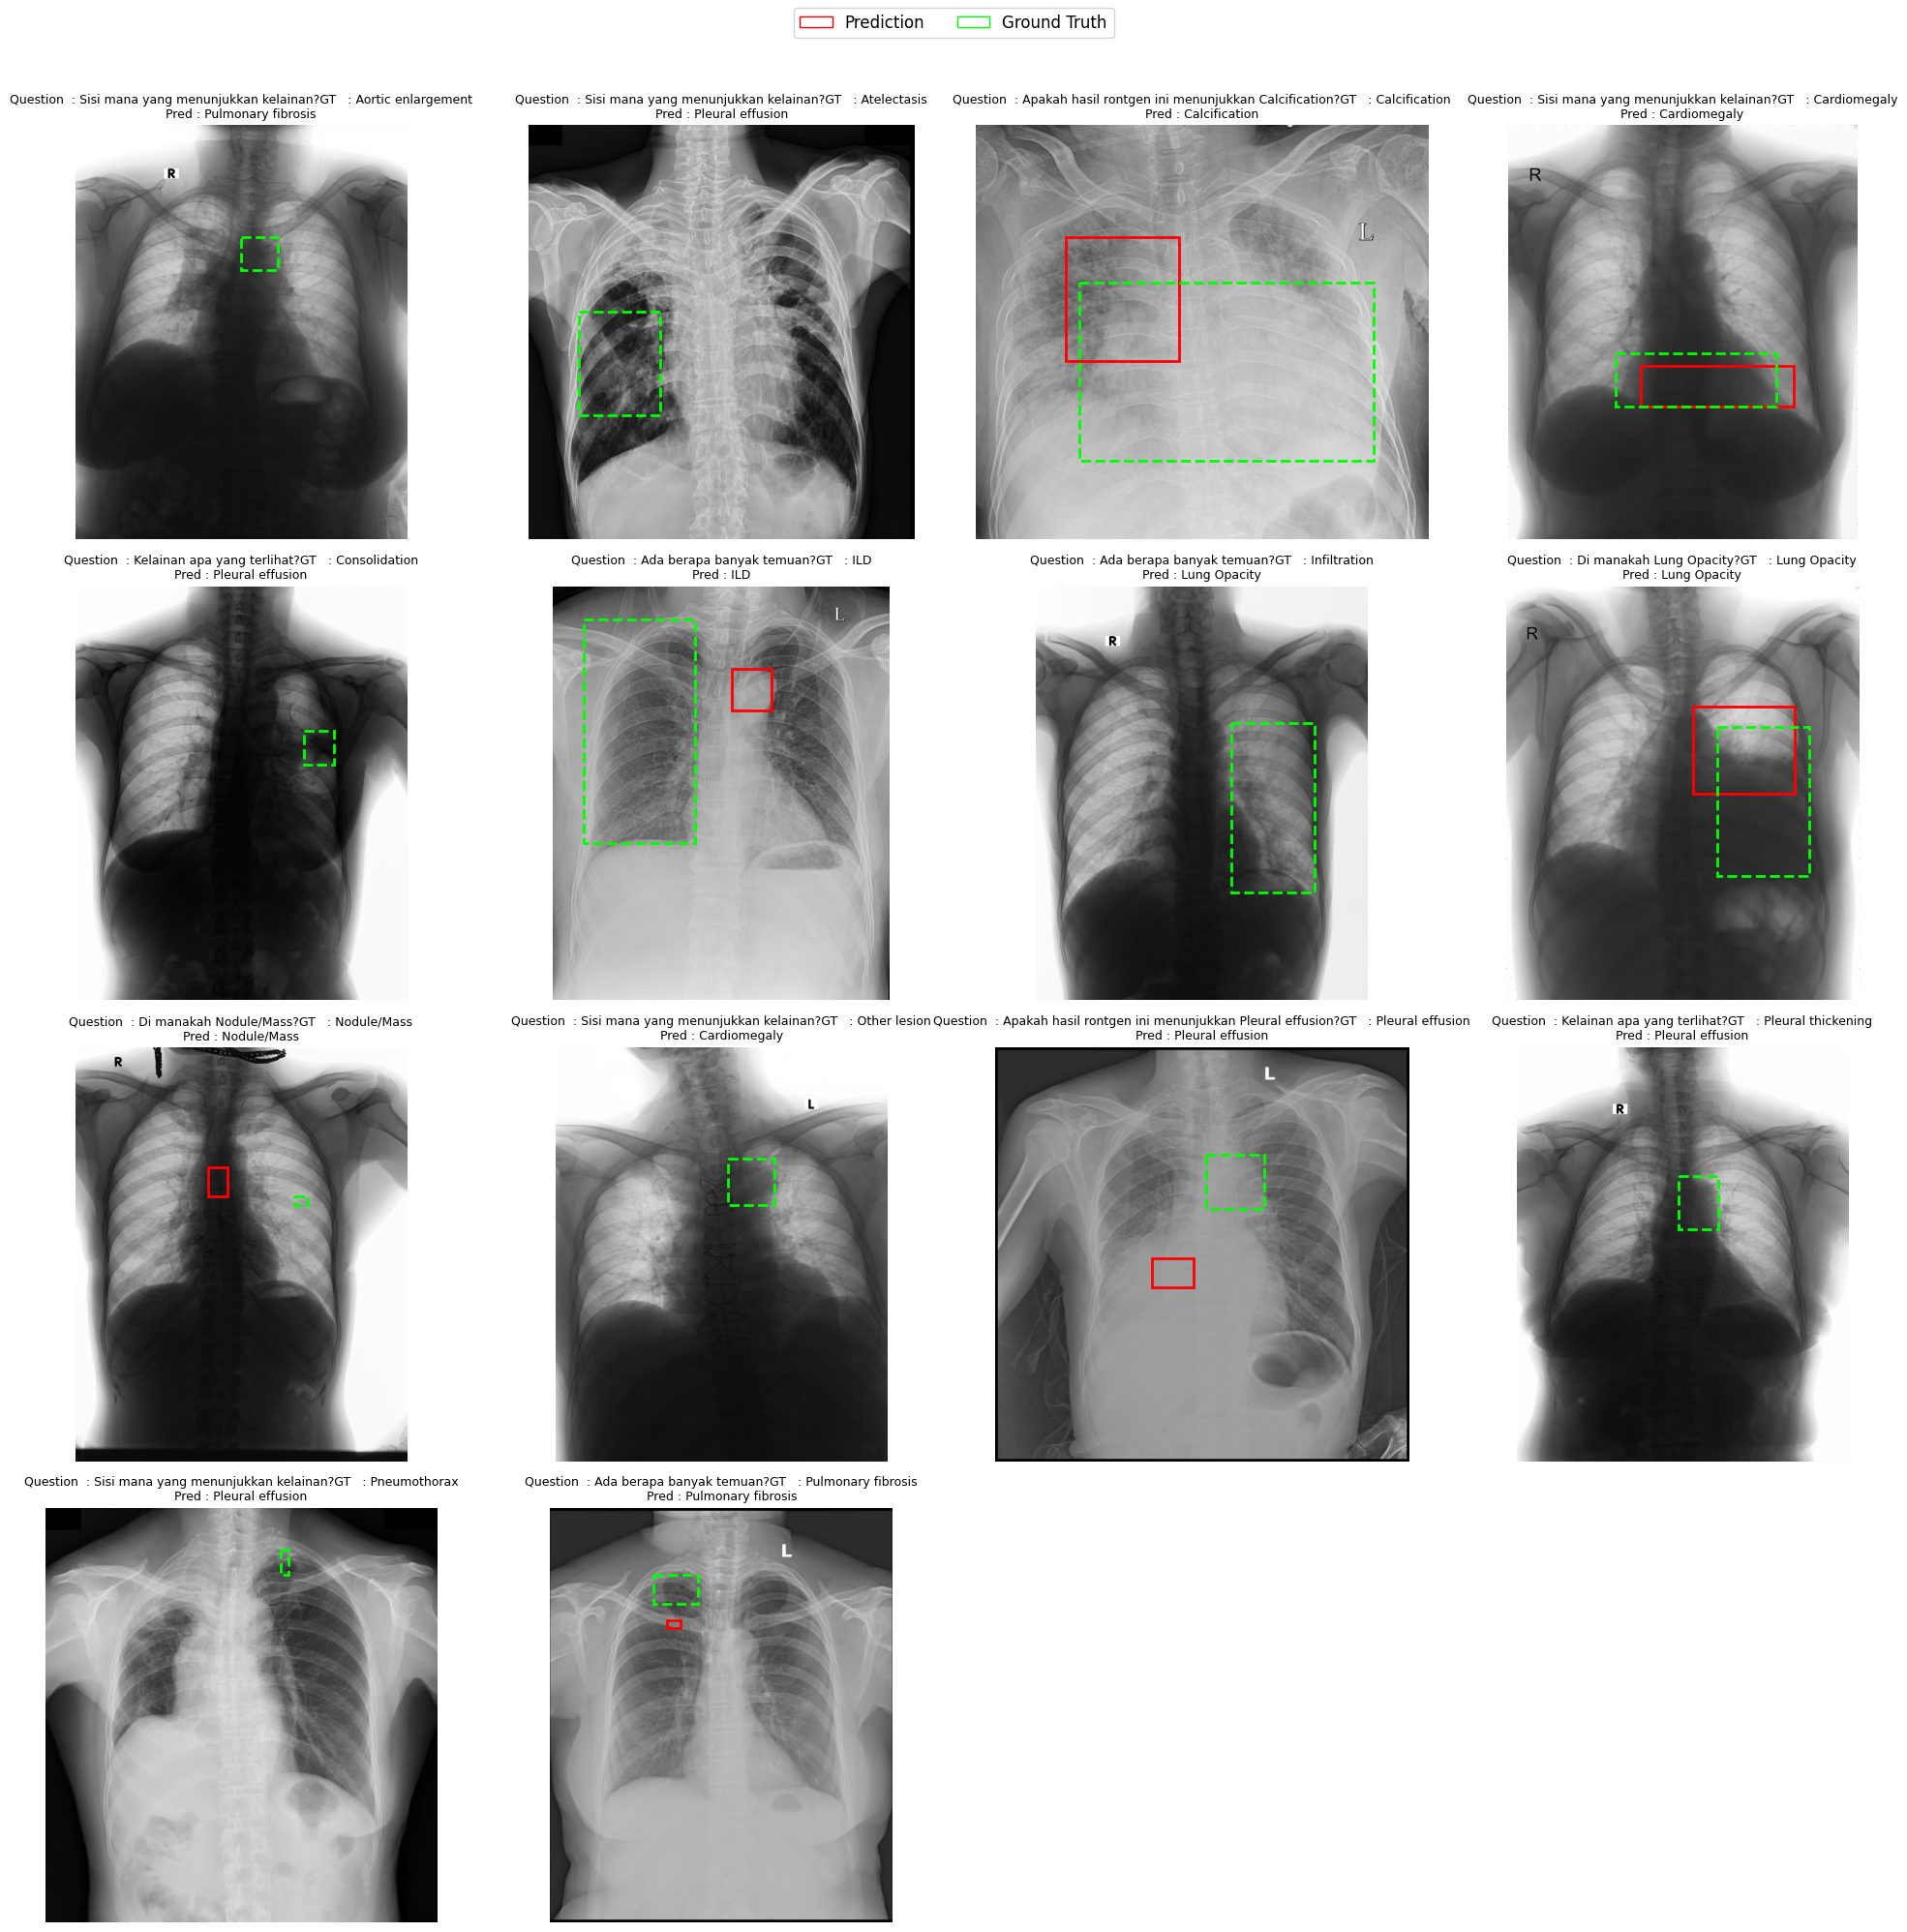

In [ ]:
import math
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

n = len(samples)

results_response =[]

cols = 4                       # jumlah kolom
rows = math.ceil(n / cols)     # jumlah baris

fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 5*rows))
axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):

    gt_label = row["gt_label"]
    gt_box = parse_bbox_by_label(row["response"], gt_label)

    result = predict(
        row["image_id"],
        row["query"],
        target_label=gt_label
    )

    img = result["image"]
    w, h = img.size

    ax.imshow(img, cmap="gray")
    pred_label = parse_label(result["response"])

    ax.set_title(
        f"Question  : {row['query']}"
        f"GT   : {gt_label}\n"
        f"Pred : {pred_label if pred_label else '-'}",
        fontsize=9
    )

    # Prediksi (merah)
    if result["bbox"] is not None:
        x1, y1, x2, y2 = [v/100 for v in result["bbox"]]

        ax.add_patch(
            mpatches.Rectangle(
                (x1*w, y1*h),
                (x2-x1)*w,
                (y2-y1)*h,
                edgecolor="red",
                linewidth=2,
                facecolor="none"
            )
        )

    # Ground Truth (hijau)
    if gt_box is not None:
        gx1, gy1, gx2, gy2 = [v/100 for v in gt_box]

        ax.add_patch(
            mpatches.Rectangle(
                (gx1*w, gy1*h),
                (gx2-gx1)*w,
                (gy2-gy1)*h,
                edgecolor="lime",
                linewidth=2,
                linestyle="--",
                facecolor="none"
            )
        )
    results_response.append(result)
    # tampilkan IoU
    if result["bbox"] is not None and gt_box is not None:
        iou = compute_iou(result["bbox"], gt_box)
        ax.set_xlabel(f"IoU={iou:.2f}", fontsize=9)

    ax.axis("off")


# Hapus subplot kosong
for ax in axes[n:]:
    ax.remove()

# Legend global
pred_patch = mpatches.Patch(edgecolor="red", facecolor="none", label="Prediction")
gt_patch = mpatches.Patch(edgecolor="lime", facecolor="none", label="Ground Truth")

fig.legend(
    handles=[pred_patch, gt_patch],
    loc="upper center",
    ncol=2,
    fontsize=12
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## STEP 13 — Batch Evaluasi IoU

In [ ]:
def parse_all_labels(text):
    return [
        label.strip()
        for label in re.findall(
            r"<\|ref\|>\s*(.*?)\s*<\|/ref\|>",
            str(text)
        )
    ]


def evaluate_sample(row):
    # Ground Truth
    gt_label = parse_label(row["response"])
    gt_box = parse_bbox_by_label(row["response"], gt_label)

    # Prediksi
    result = predict(
        row["image_id"],
        row["query"],
        target_label=gt_label
    )

    pred_box = result["bbox"]

    # Semua label yang diprediksi
    pred_labels = parse_all_labels(result["response"])

    # Apakah GT label muncul pada prediksi
    label_match = any(
        label.lower() == gt_label.lower()
        for label in pred_labels
    )

    # IoU
    if pred_box is None or gt_box is None:
        iou = 0.0
    else:
        iou = compute_iou(pred_box, gt_box)

    return {
        "image_id": row["image_id"],
        "query": row["query"],
        "gt_label": gt_label,
        "pred_labels": pred_labels,
        "gt_bbox": gt_box,
        "pred_bbox": pred_box,
        "iou": iou,
        "label_match": label_match,
        "response": result["response"]
    }

In [ ]:
len(test_df)

1480

In [ ]:
test_df.isna().sum()

image_id    0
query       0
response    0
gt_label    0
dtype: int64

In [ ]:
test_df = test_df.dropna(subset=["gt_label"]).reset_index(drop=True)

In [ ]:
records = []

for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Evaluating"):

    # Ground Truth
    gt_label = parse_label(row["response"])
    gt_box = parse_bbox_by_label(row["response"], gt_label)

    # Prediksi
    res = predict(
        row["image_id"],
        row["query"],
        target_label=gt_label
    )

    pred_box = res["bbox"]

    # Semua label yang diprediksi
    pred_labels = parse_all_labels(res["response"])

    # Apakah GT label muncul pada prediksi
    label_match = any(
        label.lower() == gt_label.lower()
        for label in pred_labels
    )

    # Hitung IoU
    if pred_box is None or gt_box is None:
        iou = 0.0
    else:
        iou = compute_iou(pred_box, gt_box)

    records.append({
        "image_id": row["image_id"],
        "query": row["query"],
        "gt_label": gt_label,
        "pred_labels": pred_labels,
        "gt_bbox": gt_box,
        "pred_bbox": pred_box,
        "pred_text": res["response"],
        "label_match": label_match,
        "iou": iou,
    })


results_df = pd.DataFrame(records)

Evaluating: 100%|██████████| 1480/1480 [2:16:03<00:00,  5.52s/it] 


In [ ]:
print(f"Total sampel      : {len(results_df)}")
print(f"Label Accuracy    : {results_df['label_match'].mean()*100:.2f}%")
print(f"Mean IoU          : {results_df['iou'].mean():.4f}")
print(f"Median IoU        : {results_df['iou'].median():.4f}")
print(f"IoU@0.5           : {(results_df['iou'] >= 0.5).mean()*100:.2f}%")
print(f"IoU@0.25          : {(results_df['iou'] >= 0.25).mean()*100:.2f}%")

Total sampel      : 1480
Label Accuracy    : 79.46%
Mean IoU          : 0.1152
Median IoU        : 0.0000
IoU@0.5           : 9.19%
IoU@0.25          : 20.41%


In [ ]:
miou_per_label = (
    results_df
    .groupby("gt_label")["iou"]
    .mean()
    .sort_values(ascending=False)
)
print("mIoU per Kelas")
print(miou_per_label)

mIoU per Kelas
gt_label
Cardiomegaly          0.192488
Pneumothorax          0.153723
Consolidation         0.128312
Other lesion          0.127093
Lung Opacity          0.120950
Infiltration          0.113938
Calcification         0.095672
Aortic enlargement    0.090941
Pulmonary fibrosis    0.075860
Pleural effusion      0.059967
Nodule/Mass           0.050374
Pleural thickening    0.035127
ILD                   0.005238
Atelectasis           0.000000
Name: iou, dtype: float64


In [ ]:
count_per_label = (
    results_df
    .groupby("gt_label")["iou"]
    .count()
    .sort_values(ascending=False)
)
print("jumlah per Kelas")
print(count_per_label)

jumlah per Kelas
gt_label
Cardiomegaly          385
Pulmonary fibrosis    231
Pleural effusion      194
Lung Opacity          185
Aortic enlargement    154
Calcification          91
Other lesion           89
Pleural thickening     35
Infiltration           30
Nodule/Mass            26
ILD                    23
Pneumothorax           23
Consolidation          10
Atelectasis             4
Name: iou, dtype: int64


In [ ]:
out = os.path.join(OUTPUT_DIR, "test_results.csv")
results_df.to_csv(out, index=False)
print(f"Disimpan: {out}")

Disimpan: ./output-indo2\test_results.csv


In [ ]:
torch.save(model.state_dict(), "chexagent_finetuned_eng.pt")

---
## Checklist Sebelum Run di Kaggle

| # | Yang harus dilakukan | Cara |
|---|---|---|
| 1 | Upload file DICOM VinDR | Kaggle → Datasets → New Dataset → upload zip |
| 2 | Upload train/val/test.parquet | Kaggle → Datasets → New Dataset terpisah |
| 3 | Tambah kedua dataset ke notebook | Notebook → Add Data → Your Datasets |
| 4 | Set Accelerator = GPU T4 x1 | Notebook → Settings → Accelerator |
| 5 | Set Internet = On | Notebook → Settings → Internet |
| 6 | Tambah HFTOKEN ke Secrets | Settings → Add-ons → Secrets → Add |
| 7 | Sesuaikan `DICOM_DIR` dan `DATASET_PATH` | STEP 4 — cek output listdir |

## Estimasi Waktu di Kaggle T4

| | Lokal RTX 3060 | Kaggle T4 |
|---|---|---|
| VRAM | 6.4 GB (tidak cukup) | 15 GB ✅ |
| Detik/iter | ~550 det (CPU) | ~8-15 det |
| Total 5 epoch | ~632 jam | ~11-17 jam |
| Batas Kaggle | — | 30 jam/minggu |